In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from gm.data.example_2d import sample_data, sample_noise

from gm.models.flow_matching_model import FlowMatchingModel, train_fmm, sample_fmm

In [17]:
N = 5_000
SEED = 42
DEVICE = 'mps'

steps = 5_000
batch_size = 256
lr = 1e-3

In [18]:
fmm = FlowMatchingModel().to(DEVICE)
opt = torch.optim.Adam(fmm.parameters(), lr)
losses = train_fmm(fmm, opt, sample_noise, sample_data, steps, batch_size, DEVICE)

100%|██████████| 5000/5000 [00:19<00:00, 261.25it/s, Loss=1.02]


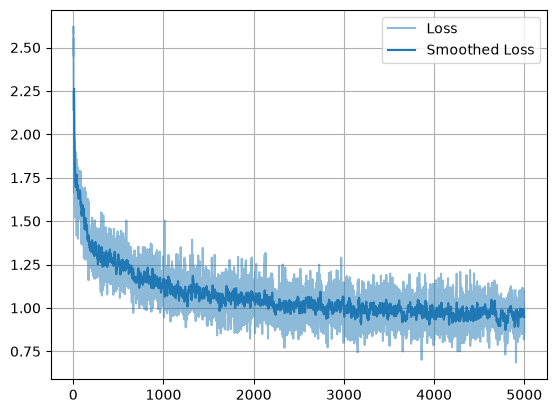

In [19]:
fig, ax = plt.subplots()

ax.plot(losses, label="Loss", color="tab:blue", alpha=0.5)
ws = 10
smoothed = np.convolve(losses, np.ones(ws)/ws, mode="valid")
ax.plot(np.arange(ws-1, len(losses)), smoothed, label="Smoothed Loss", color="tab:blue")

plt.legend()
plt.grid()
plt.show()

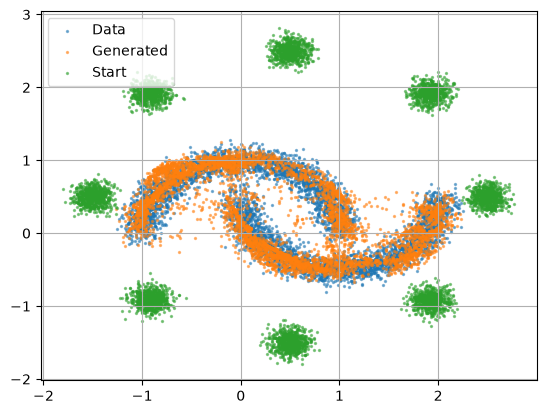

In [20]:
fmm.eval()

data = sample_data(N)
x_0 = sample_noise(N).to(DEVICE)

samples = sample_fmm(fmm, x_0, n_steps=100, device=DEVICE).cpu()
x_0 = x_0.detach().cpu()


fig, ax = plt.subplots()

ax.scatter(data[:, 0], data[:, 1], alpha=0.5, s=2, label="Data")
ax.scatter(samples[:, 0], samples[:, 1], alpha=0.5, s=2, label="Generated")
ax.scatter(x_0[:, 0], x_0[:, 1], alpha=0.5, s=2, label="Start")

plt.legend()
plt.grid()
plt.show()